In [37]:
from typing import TypedDict
from langgraph.graph import START, StateGraph, END
from langchain_groq import ChatGroq
from dotenv import load_dotenv
load_dotenv()

True

In [38]:
llm = ChatGroq(model='qwen/qwen3.8-27b', temperature=1)
llm_content = ChatGroq(model='openai/gpt-oss-120b', temperature=1)

In [39]:
# define State
class BLOGState(TypedDict):
    title : str
    outline : str
    content : str

In [44]:
def outline_node(state: BLOGState) -> BLOGState:

    title = state['title']
    prompt = (f'''
    You are an expert content strategist and writer.

    I will give you a title/topic. Create a clear, logical, and comprehensive outline for the content.

    Title: {title}

    Requirements:

    * Identify the main purpose and search intent behind the title.
    * Define the target audience based on the topic.
    * Create a logical structure that flows naturally from introduction to conclusion.
    * Include an engaging introduction section.
    * Break the main topic into relevant H2 sections.
    * Add useful H3 subsections under H2s where appropriate.
    * Cover important questions, concepts, examples, benefits, drawbacks, practical tips, and related points when relevant.
    * Avoid unnecessary or repetitive sections.
    * Make the outline comprehensive enough to support a detailed, high-quality article.
    * Arrange sections in the order that makes the most sense for the reader.
    * Include a brief description of what should be covered in each section.
    * If the topic is suitable for SEO, naturally include relevant subtopics and related search queries without keyword stuffing.

    Output format:

    # [Title]

    ## Introduction

    * What the introduction should cover

    ## H2: [Main Section]

    * Key points to discuss
    * Important details/examples

    ### H3: [Subsection]

    * Key points to discuss

    ## H2: [Main Section]

    * Key points to discuss

    ## Conclusionz

    * What the conclusion should summarize
    * Final takeaway or recommendation

    Do not write the full article. Only provide the outline.
    Important rule: 
        result will be less then 1000 tokens.
        

    ''')
    response = llm.invoke(prompt).content
    state['outline'] = response
    return state

In [45]:
def content_node(state: BLOGState) -> BLOGState:

    title = state['title']
    outline = state['outline']

    prompt = f'''
        You are an expert writer and subject-matter researcher.

    Using the outline below, write a complete, original, well-structured piece of content.

    Title: {title}

    Outline:
    [{outline}]

    Requirements:

    * Follow the outline closely, but expand each section naturally.
    * Write for the intended target audience.
    * Start with a strong, engaging introduction that clearly explains what the reader will learn.
    * Use clear H2 and H3 headings matching the outline.
    * Explain concepts thoroughly but avoid unnecessary repetition or filler.
    * Use simple, natural, and easy-to-understand language.
    * Provide practical examples wherever they improve understanding.
    * Use short paragraphs for readability.
    * Use bullet points or numbered lists when they make information easier to understand.
    * Maintain a logical flow between sections.
    * Include useful details, insights, and actionable advice.
    * Do not make unsupported claims or invent statistics, studies, quotes, or sources.
    * Keep the writing natural and human-sounding rather than robotic or formulaic.
    * Avoid excessive keyword repetition or obvious SEO stuffing.
    * Answer the reader's likely questions throughout the content.
    * End with a concise conclusion that reinforces the main takeaway.
    * Do not mention that you are an AI.
    * Do not mention these instructions or the outline-generation process.

    Before writing, silently identify any gaps or inconsistencies in the outline and resolve them in the most logical way.

    Output only the finished content.

    '''
    response = llm_content.invoke(prompt).content
    state['content'] = response
    return state

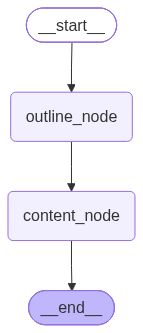

In [46]:
# Graph
graph = StateGraph(BLOGState)

graph.add_node('outline_node', outline_node)
graph.add_node('content_node', content_node)

graph.add_edge(START, 'outline_node')
graph.add_edge('outline_node', 'content_node')
graph.add_edge('content_node', END)

workflow = graph.compile()
workflow

In [47]:
results = workflow.invoke({
    'title': "How to Build a Personal Brand Online: A Complete Beginner's Guide"
})
results

{'title': "How to Build a Personal Brand Online: A Complete Beginner's Guide",
 'outline': '# How to Build a Personal Brand Online: A Complete Beginner\'s Guide\n\n## Search Intent & Target Audience\n*   **Intent:** Informational/Transactional. The user seeks a step-by-step roadmap to establishing an authentic digital presence, seeking actionable tactics for visibility and credibility.\n*   **Audience:** Beginners, career switchers, freelancers, and early-stage entrepreneurs who feel overwhelmed by the noise and lack a clear strategy.\n\n## Introduction\n*   **Hook:** Address the "sea of sameness" on social media; explain why authenticity beats perfection.\n*   **Promise:** Provide a clear, low-cost framework to go from invisible to influential.\n*   **Relevance:** Define what a personal brand actually is (reputation + perception) versus just a logo or website. Ensure the reader understands the long-term value (career growth, business opportunities).\n\n## H2: Defining Your Core: Niche

In [51]:
print(results['outline'])

# How to Build a Personal Brand Online: A Complete Beginner's Guide

## Search Intent & Target Audience
*   **Intent:** Informational/Transactional. The user seeks a step-by-step roadmap to establishing an authentic digital presence, seeking actionable tactics for visibility and credibility.
*   **Audience:** Beginners, career switchers, freelancers, and early-stage entrepreneurs who feel overwhelmed by the noise and lack a clear strategy.

## Introduction
*   **Hook:** Address the "sea of sameness" on social media; explain why authenticity beats perfection.
*   **Promise:** Provide a clear, low-cost framework to go from invisible to influential.
*   **Relevance:** Define what a personal brand actually is (reputation + perception) versus just a logo or website. Ensure the reader understands the long-term value (career growth, business opportunities).

## H2: Defining Your Core: Niche and Value Proposition
*   **Key Points:** You cannot brand nothing. Identify your unique intersection o

In [52]:
print(results['content'])

# How to Build a Personal Brand Online: A Complete Beginner's Guide  

---

## Search Intent & Target Audience  
* **Intent:** Informational/Transactional – you’re looking for a step‑by‑step roadmap to create an authentic digital presence that drives visibility and credibility.  
* **Audience:** Beginners, career switchers, freelancers, and early‑stage entrepreneurs who feel overwhelmed by the noise and need a clear, low‑cost strategy.  

---

## Introduction  

Scrolling through feeds filled with perfectly curated lives can feel like swimming in a sea of sameness. It’s easy to wonder: *If everyone looks the same, how can I stand out?*  

The truth is that authenticity, not perfection, is the magnetic force that pulls people toward you. When you share who you truly are—your struggles, insights, and unique way of solving problems—your audience connects on a human level and remembers you.  

In this guide you’ll discover a practical, low‑budget framework that takes you from “invisible” t